# 1.Data prepration

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from xgboost import XGBRegressor

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
df = pd.read_csv("all_currencies.csv")

print("Dataset loaded successfully!")

print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (645784, 9)


,Unnamed: 0,Date,Symbol,Open,High,Low,Close,Volume,Market Cap
0,0,2015-11-12,$$$,0.000013,0.000017,0.000013,0.000017,142.0,NaN
1,1,2015-11-13,$$$,0.000017,0.000033,0.000016,0.000024,85.0,NaN
2,2,2015-11-14,$$$,0.000024,0.000053,0.000023,0.000030,131.0,NaN
3,3,2015-11-15,$$$,0.000030,0.000063,0.000022,0.000035,132.0,NaN
4,4,2015-11-16,$$$,0.000035,0.000046,0.000032,0.000036,280.0,NaN


In [3]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

# Remove unnecessary index column

df.drop(
    columns=["unnamed_0"],
    errors="ignore",
    inplace=True
)

# Convert date

df["date"] = pd.to_datetime(
    df["date"],
    errors="coerce"
)

# Standardize cryptocurrency symbols

df["symbol"] = df["symbol"].astype(str).str.upper().str.strip()

# Remove invalid dates

df.dropna(subset=["date"], inplace=True)

print("Updated Columns:")

print(df.columns.tolist())

display(df.head())

Updated Columns:
['date', 'symbol', 'open', 'high', 'low', 'close', 'volume', 'market_cap']


,date,symbol,open,high,low,close,volume,market_cap
0,2015-11-12,$$$,0.000013,0.000017,0.000013,0.000017,142.0,NaN
1,2015-11-13,$$$,0.000017,0.000033,0.000016,0.000024,85.0,NaN
2,2015-11-14,$$$,0.000024,0.000053,0.000023,0.000030,131.0,NaN
3,2015-11-15,$$$,0.000030,0.000063,0.000022,0.000035,132.0,NaN
4,2015-11-16,$$$,0.000035,0.000046,0.000032,0.000036,280.0,NaN


In [4]:
print("DATASET INFORMATION")

print("Total Records:", len(df))

print("Total Columns:", len(df.columns))

print("Total Cryptocurrencies:", df["symbol"].nunique())

print("Starting Date:", df["date"].min())

print("Ending Date:", df["date"].max())

print("\nDataset Information:")

df.info()

print("\nStatistical Description:")

display(df.describe())

DATASET INFORMATION
Total Records: 645784
Total Columns: 8
Total Cryptocurrencies: 877
Starting Date: 2013-04-28 00:00:00
Ending Date: 2018-06-02 00:00:00

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 645784 entries, 0 to 645783
Data columns (total 8 columns):
 #   Column      Non-Null Count   Dtype         
---  ------      --------------   -----         
 0   date        645784 non-null  datetime64[us]
 1   symbol      645784 non-null  str           
 2   open        645784 non-null  float64       
 3   high        645784 non-null  float64       
 4   low         645784 non-null  float64       
 5   close       645784 non-null  float64       
 6   volume      640028 non-null  float64       
 7   market_cap  561299 non-null  float64       
dtypes: datetime64[us](1), float64(6), str(1)
memory usage: 39.4 MB

Statistical Description:


,date,open,high,low,close,volume,market_cap
count,645784,6.457840e+05,6.457840e+05,6.457840e+05,6.457840e+05,6.400280e+05,5.612990e+05
mean,2016-11-21 09:28:18.073659,1.838564e+02,2.230398e+02,1.467489e+02,1.821590e+02,7.048649e+06,1.990142e+08
min,2013-04-28 00:00:00,2.500000e-09,3.200000e-09,2.300000e-09,2.500000e-09,0.000000e+00,0.000000e+00
25%,2016-01-25 00:00:00,4.950000e-04,5.810000e-04,4.300000e-04,4.960000e-04,2.900000e+01,2.458950e+04
50%,2017-03-08 00:00:00,6.627000e-03,7.638000e-03,5.809000e-03,6.635000e-03,4.030000e+02,1.614520e+05
75%,2017-11-17 00:00:00,7.903150e-02,9.116875e-02,6.937925e-02,7.906125e-02,7.803250e+03,1.452460e+06
max,2018-06-02 00:00:00,2.298390e+06,2.926100e+06,2.030590e+06,2.300740e+06,2.384090e+10,3.261410e+11
std,NaN,8.697238e+03,1.142367e+04,6.328668e+03,8.585699e+03,1.929721e+08,4.089282e+09


In [5]:
print("MISSING VALUES")

display(df.isnull().sum())

print("\nMISSING VALUE PERCENTAGE")

display(
    (df.isnull().mean() * 100).round(2)
)

print("\nDUPLICATE RECORDS")

print(df.duplicated().sum())

MISSING VALUES


date              0
symbol            0
open              0
high              0
low               0
close             0
volume         5756
market_cap    84485
dtype: int64


MISSING VALUE PERCENTAGE


date           0.00
symbol         0.00
open           0.00
high           0.00
low            0.00
close          0.00
volume         0.89
market_cap    13.08
dtype: float64


DUPLICATE RECORDS
0


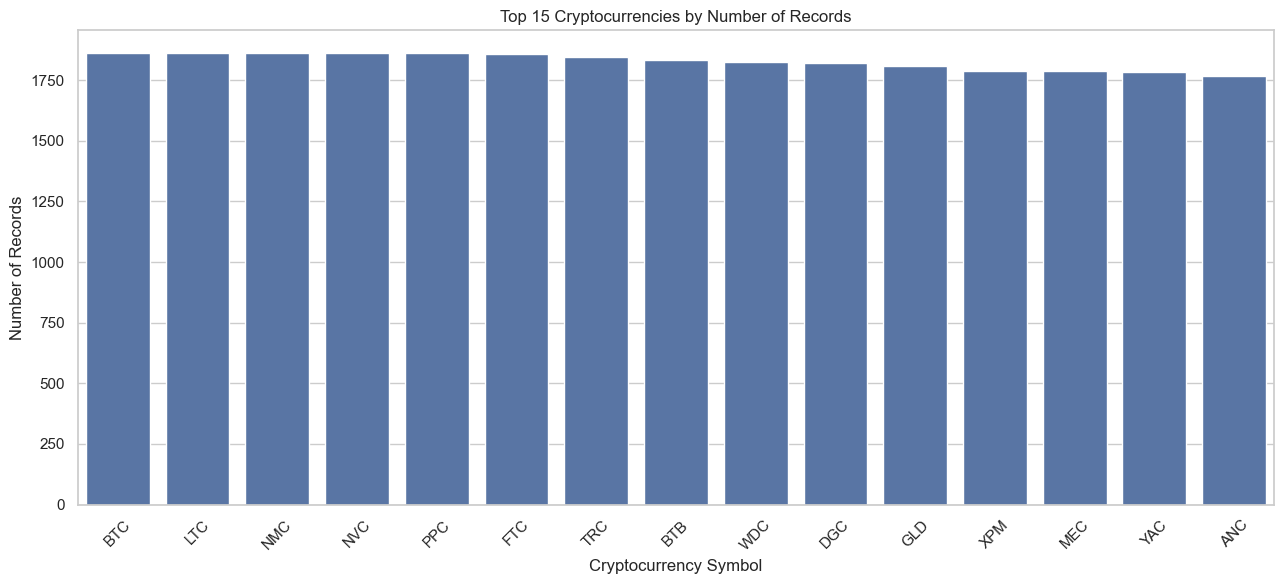

In [6]:
coin_counts = (
    df["symbol"]
    .value_counts()
    .head(15)
)

plt.figure(figsize=(13, 6))

sns.barplot(
    x=coin_counts.index,
    y=coin_counts.values
)

plt.title("Top 15 Cryptocurrencies by Number of Records")

plt.xlabel("Cryptocurrency Symbol")

plt.ylabel("Number of Records")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

In [7]:
# Select cryptocurrency

COIN_SYMBOL = "BTC"

coin = df[
    df["symbol"] == COIN_SYMBOL
].copy()

# Sort by date

coin = coin.sort_values("date")

# Remove duplicate dates

coin = coin.drop_duplicates(
    subset=["date"],
    keep="last"
)

coin.reset_index(
    drop=True,
    inplace=True
)

print("Selected Cryptocurrency:", COIN_SYMBOL)

print("Total Records:", len(coin))

print("Starting Date:", coin["date"].min())

print("Ending Date:", coin["date"].max())

display(coin.head())

Selected Cryptocurrency: BTC
Total Records: 1862
Starting Date: 2013-04-28 00:00:00
Ending Date: 2018-06-02 00:00:00


,date,symbol,open,high,low,close,volume,market_cap
0,2013-04-28,BTC,135.30,135.98,132.10,134.21,NaN,1.500520e+09
1,2013-04-29,BTC,134.44,147.49,134.00,144.54,NaN,1.491160e+09
2,2013-04-30,BTC,144.00,146.93,134.05,139.00,NaN,1.597780e+09
3,2013-05-01,BTC,139.00,139.89,107.72,116.99,NaN,1.542820e+09
4,2013-05-02,BTC,116.38,125.60,92.28,105.21,NaN,1.292190e+09


In [8]:
COIN_SYMBOL = "ETH"

print(sorted(df["symbol"].unique()))

['$$$', '$PAC', '1337', '2GIVE', '42', '611', '808', '888', '8BIT', 'ABJ', 'ABY', 'AC', 'ACC', 'ACES', 'ACN', 'ACOIN', 'ACP', 'ACT', 'ADA', 'ADC', 'ADCN', 'ADK', 'ADZ', 'AEON', 'AERM', 'AGLC', 'AIB', 'AKY', 'ALL', 'ALQO', 'AMBER', 'AMMO', 'AMS', 'ANC', 'ANI', 'ANTX', 'APC', 'ARB', 'ARC', 'ARCO', 'ARDR', 'ARG', 'ARGUS', 'ARI', 'ARK', 'ASAFE2', 'ASN', 'ATB', 'ATC', 'ATMC', 'ATMOS', 'ATOM', 'ATX', 'AU', 'AUR', 'AV', 'AXIOM', 'B2X', 'BASH', 'BAT', 'BAY', 'BBP', 'BBR', 'BCA', 'BCC', 'BCD', 'BCF', 'BCH', 'BCI', 'BCN', 'BCO', 'BCX', 'BDL', 'BENJI', 'BERN', 'BEST', 'BET', 'BIGUP', 'BIO', 'BIOB', 'BIOS', 'BIP', 'BIRDS', 'BIS', 'BIT', 'BITB', 'BITG', 'BITOK', 'BITS', 'BITZ', 'BLAZR', 'BLC', 'BLITZ', 'BLK', 'BLOCK', 'BLU', 'BLZ', 'BNX', 'BOAT', 'BOLI', 'BOS', 'BOST', 'BPL', 'BRIA', 'BRIT', 'BRK', 'BRO', 'BRX', 'BSC', 'BSD', 'BSM', 'BSN', 'BSR', 'BSTAR', 'BSTY', 'BT2', 'BTA', 'BTB', 'BTBC', 'BTC', 'BTCD', 'BTCP', 'BTCR', 'BTCS', 'BTCZ', 'BTDX', 'BTG', 'BTM', 'BTPL', 'BTQ', 'BTS', 'BTW', 'BTX', 'BU

In [9]:
numeric_columns = [
    "open",
    "high",
    "low",
    "close",
    "volume",
    "market_cap"
]

for col in numeric_columns:

    coin[col] = pd.to_numeric(
        coin[col],
        errors="coerce"
    )

# Remove invalid OHLC records

valid_ohlc = (
    (coin[["open", "high", "low", "close"]] > 0).all(axis=1)
)

valid_ohlc &= (
    coin["high"] >= coin[["open", "close", "low"]].max(axis=1)
)

valid_ohlc &= (
    coin["low"] <= coin[["open", "close", "high"]].min(axis=1)
)

coin = coin.loc[valid_ohlc].copy()

# Record missing-value indicators

coin["volume_missing"] = (
    coin["volume"].isna().astype(int)
)

coin["market_cap_missing"] = (
    coin["market_cap"].isna().astype(int)
)

# Forward-fill using previous available values

coin["volume"] = coin["volume"].ffill().fillna(0)

coin["market_cap"] = (
    coin["market_cap"].ffill().fillna(0)
)

print("Cleaning completed!")

print("Remaining Records:", len(coin))

display(coin.head())

Cleaning completed!
Remaining Records: 1862


,date,symbol,open,high,low,close,volume,market_cap,volume_missing,market_cap_missing
0,2013-04-28,BTC,135.30,135.98,132.10,134.21,0.0,1.500520e+09,1,0
1,2013-04-29,BTC,134.44,147.49,134.00,144.54,0.0,1.491160e+09,1,0
2,2013-04-30,BTC,144.00,146.93,134.05,139.00,0.0,1.597780e+09,1,0
3,2013-05-01,BTC,139.00,139.89,107.72,116.99,0.0,1.542820e+09,1,0
4,2013-05-02,BTC,116.38,125.60,92.28,105.21,0.0,1.292190e+09,1,0


# 2.EDA

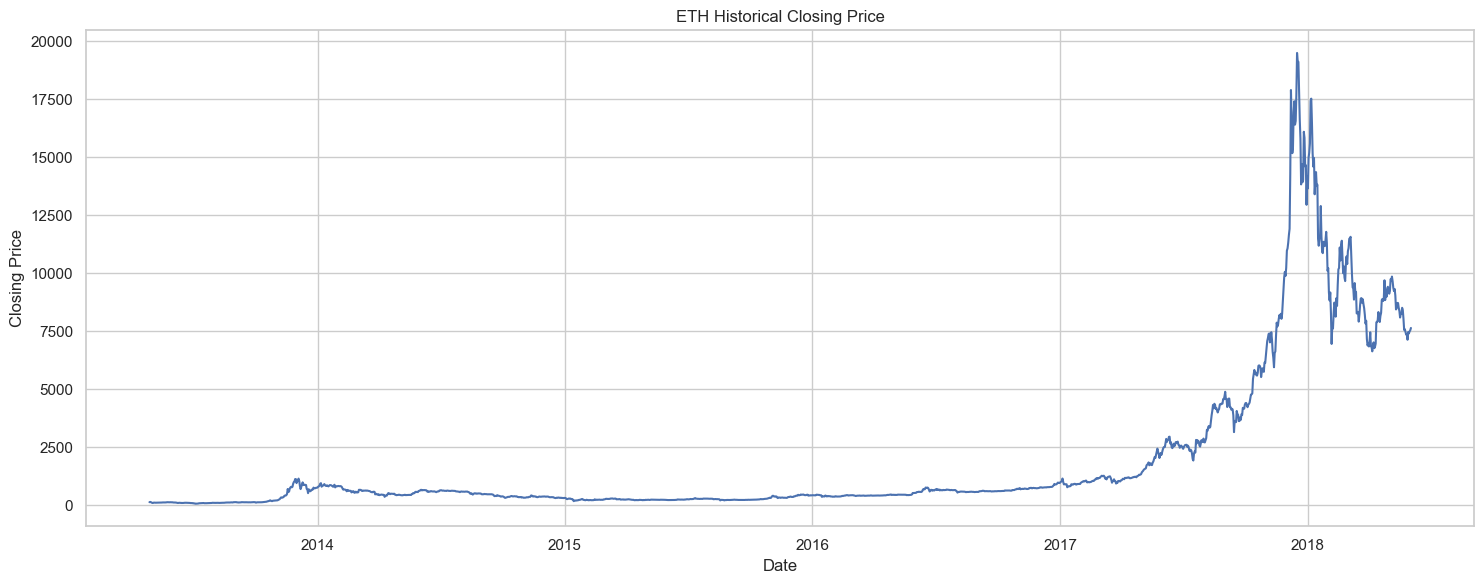

In [10]:
plt.figure(figsize=(15, 6))

plt.plot(
    coin["date"],
    coin["close"],
    linewidth=1.5
)

plt.title(
    f"{COIN_SYMBOL} Historical Closing Price"
)

plt.xlabel("Date")

plt.ylabel("Closing Price")

plt.tight_layout()

plt.show()

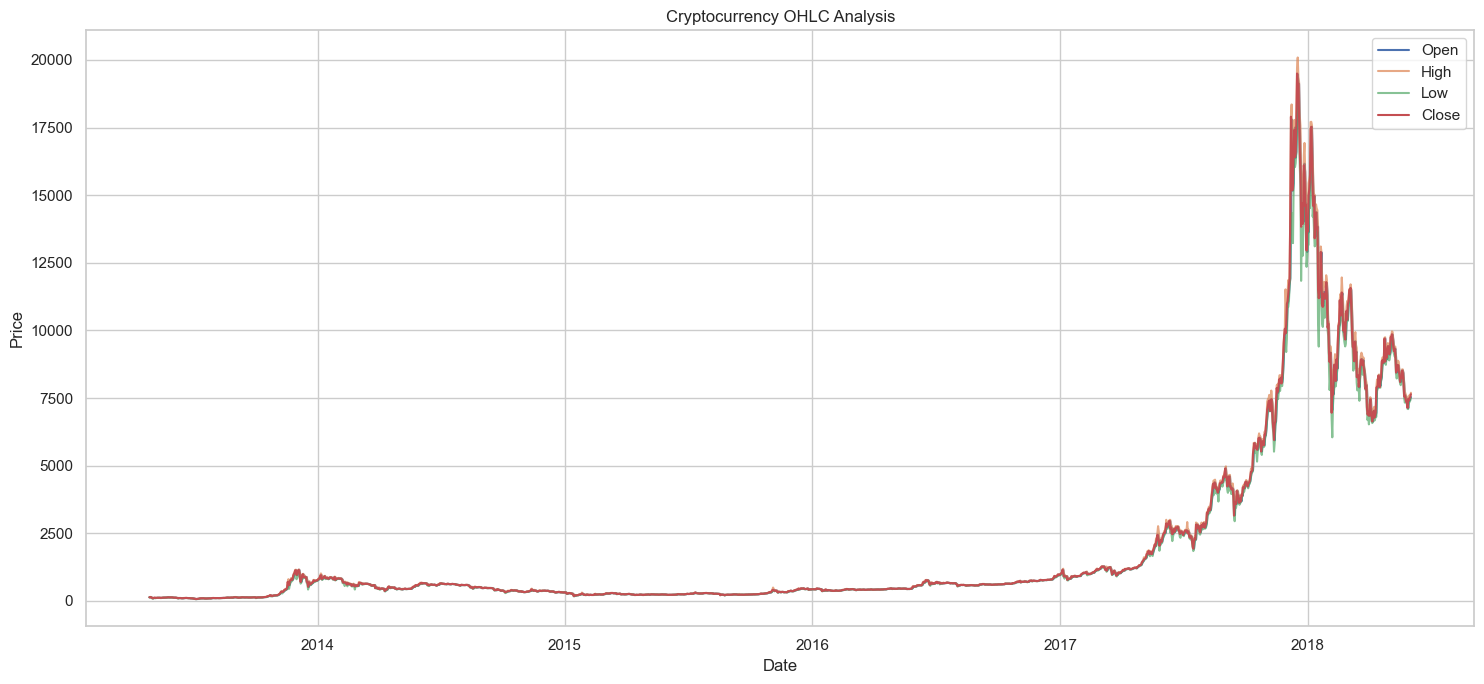

In [11]:
plt.figure(figsize=(15, 7))

plt.plot(
    coin["date"],
    coin["open"],
    label="Open"
)

plt.plot(
    coin["date"],
    coin["high"],
    label="High",
    alpha=0.7
)

plt.plot(
    coin["date"],
    coin["low"],
    label="Low",
    alpha=0.7
)

plt.plot(
    coin["date"],
    coin["close"],
    label="Close"
)

plt.title("Cryptocurrency OHLC Analysis")

plt.xlabel("Date")

plt.ylabel("Price")

plt.legend()

plt.tight_layout()

plt.show()

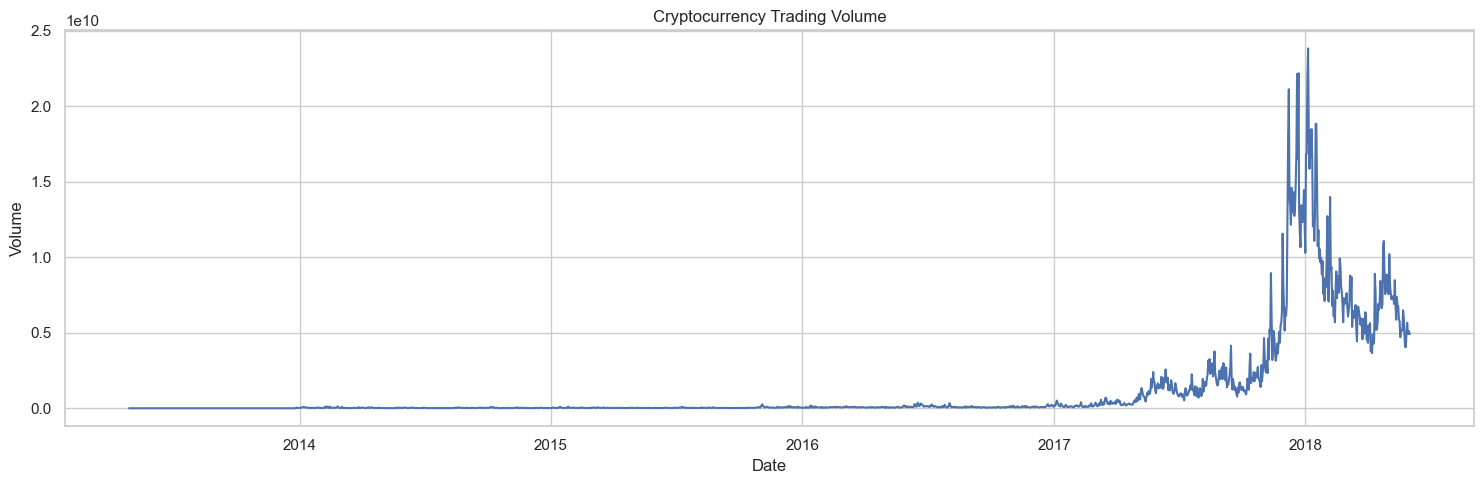

In [12]:
plt.figure(figsize=(15, 5))

plt.plot(
    coin["date"],
    coin["volume"]
)

plt.title("Cryptocurrency Trading Volume")

plt.xlabel("Date")

plt.ylabel("Volume")

plt.tight_layout()

plt.show()

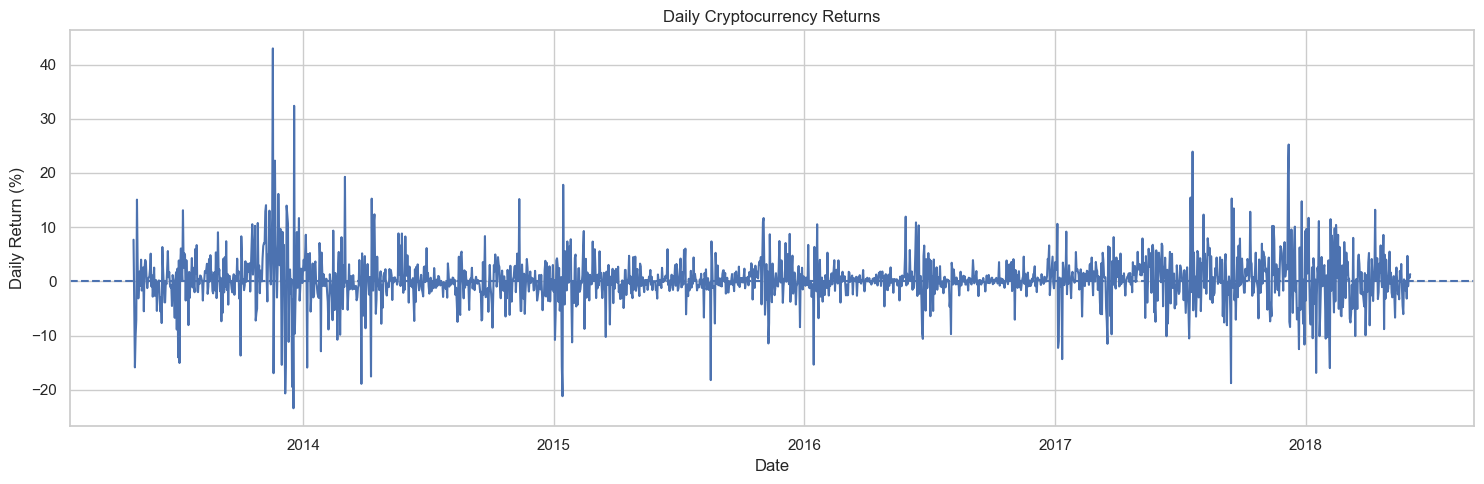

In [13]:
coin["returns"] = coin["close"].pct_change()

coin["log_returns"] = np.log(
    coin["close"]
).diff()

plt.figure(figsize=(15, 5))

plt.plot(
    coin["date"],
    coin["returns"] * 100
)

plt.axhline(
    0,
    linestyle="--"
)

plt.title("Daily Cryptocurrency Returns")

plt.xlabel("Date")

plt.ylabel("Daily Return (%)")

plt.tight_layout()

plt.show()

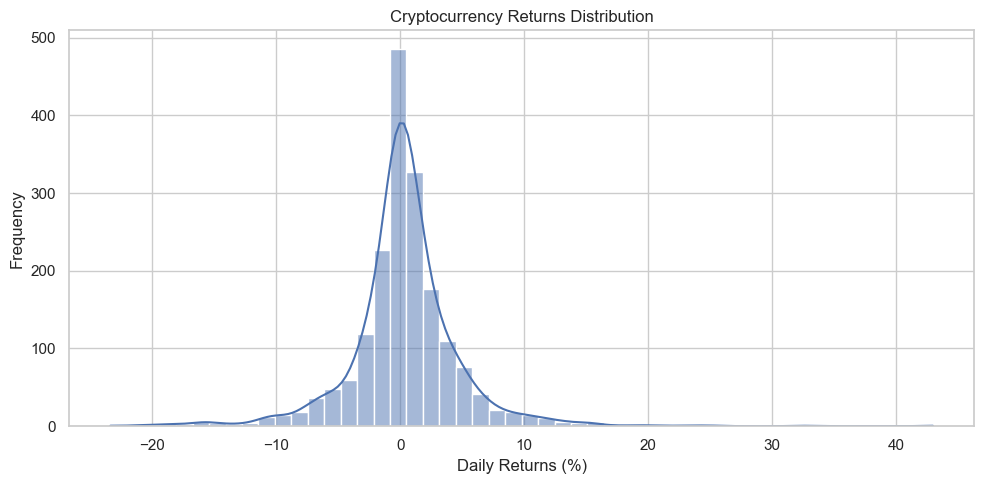

In [14]:
plt.figure(figsize=(10, 5))

sns.histplot(
    coin["returns"].dropna() * 100,
    bins=50,
    kde=True
)

plt.title("Cryptocurrency Returns Distribution")

plt.xlabel("Daily Returns (%)")

plt.ylabel("Frequency")

plt.tight_layout()

plt.show()

In [15]:
print("CRYPTOCURRENCY STATISTICAL REPORT")

print("\nMean Price:")

print(coin["close"].mean())

print("\nMedian Price:")

print(coin["close"].median())

print("\nMaximum Price:")

print(coin["close"].max())

print("\nMinimum Price:")

print(coin["close"].min())

print("\nPrice Standard Deviation:")

print(coin["close"].std())

print("\nAverage Trading Volume:")

print(coin["volume"].mean())

print("\nAverage Daily Return:")

print(coin["returns"].mean() * 100, "%")

print("\nDescriptive Statistics:")

display(
    coin[
        ["open", "high", "low", "close", "volume", "market_cap"]
    ].describe()
)

CRYPTOCURRENCY STATISTICAL REPORT

Mean Price:
1877.1805692803437

Median Price:
563.155

Maximum Price:
19497.4

Minimum Price:
68.43

Price Standard Deviation:
3316.299694507452

Average Trading Volume:
1163592548.131042

Average Daily Return:
0.317867428833131 %

Descriptive Statistics:


,open,high,low,close,volume,market_cap
count,1862.000000,1862.000000,1862.000000,1862.000000,1.862000e+03,1.862000e+03
mean,1873.425215,1939.293974,1800.072691,1877.180569,1.163593e+09,3.056875e+10
std,3314.255163,3452.230665,3145.814136,3316.299695,3.021572e+09,5.608355e+10
min,68.500000,74.560000,65.530000,68.430000,0.000000e+00,7.792550e+08
25%,284.730000,290.825000,280.642500,285.240000,1.725662e+07,4.048982e+09
50%,562.535000,575.140000,532.625000,563.155000,4.878970e+07,7.230775e+09
75%,1049.080000,1080.110000,1027.457500,1048.822500,2.409148e+08,1.691160e+10
max,19475.800000,20089.000000,18974.100000,19497.400000,2.384090e+10,3.261410e+11


# 3.Advanced Feature Engineering

In [16]:
coin["ma_7"] = (
    coin["close"].rolling(7).mean()
)

coin["ma_20"] = (
    coin["close"].rolling(20).mean()
)

coin["ma_50"] = (
    coin["close"].rolling(50).mean()
)

coin["ma_100"] = (
    coin["close"].rolling(100).mean()
)

print("Moving averages generated!")

Moving averages generated!


In [17]:
coin["ema_12"] = (
    coin["close"].ewm(
        span=12,
        adjust=False
    ).mean()
)

coin["ema_26"] = (
    coin["close"].ewm(
        span=26,
        adjust=False
    ).mean()
)

print("EMA indicators generated!")

EMA indicators generated!


In [18]:
delta = coin["close"].diff()

gain = delta.clip(lower=0)

loss = -delta.clip(upper=0)

avg_gain = gain.rolling(14).mean()

avg_loss = loss.rolling(14).mean()

rs = avg_gain / (
    avg_loss + 1e-10
)

coin["rsi"] = 100 - (
    100 / (1 + rs)
)

print("RSI generated!")

RSI generated!


In [19]:
coin["macd"] = (
    coin["ema_12"] - coin["ema_26"]
)

coin["macd_signal"] = (
    coin["macd"].ewm(
        span=9,
        adjust=False
    ).mean()
)

coin["macd_histogram"] = (
    coin["macd"] - coin["macd_signal"]
)

print("MACD generated!")

MACD generated!


In [20]:
coin["bb_middle"] = (
    coin["close"].rolling(20).mean()
)

bb_std = coin["close"].rolling(20).std()

coin["bb_upper"] = (
    coin["bb_middle"] + 2 * bb_std
)

coin["bb_lower"] = (
    coin["bb_middle"] - 2 * bb_std
)

print("Bollinger Bands generated!")

Bollinger Bands generated!


In [21]:
coin["volatility_10"] = (
    coin["returns"].rolling(10).std()
)

coin["volatility_20"] = (
    coin["returns"].rolling(20).std()
)

coin["momentum_10"] = (
    coin["close"] - coin["close"].shift(10)
)

coin["range_pct"] = (
    (coin["high"] - coin["low"])
    / coin["close"]
)

coin["close_to_ma20"] = (
    (coin["close"] / coin["ma_20"]) - 1
)

print("Volatility and momentum features generated!")

Volatility and momentum features generated!


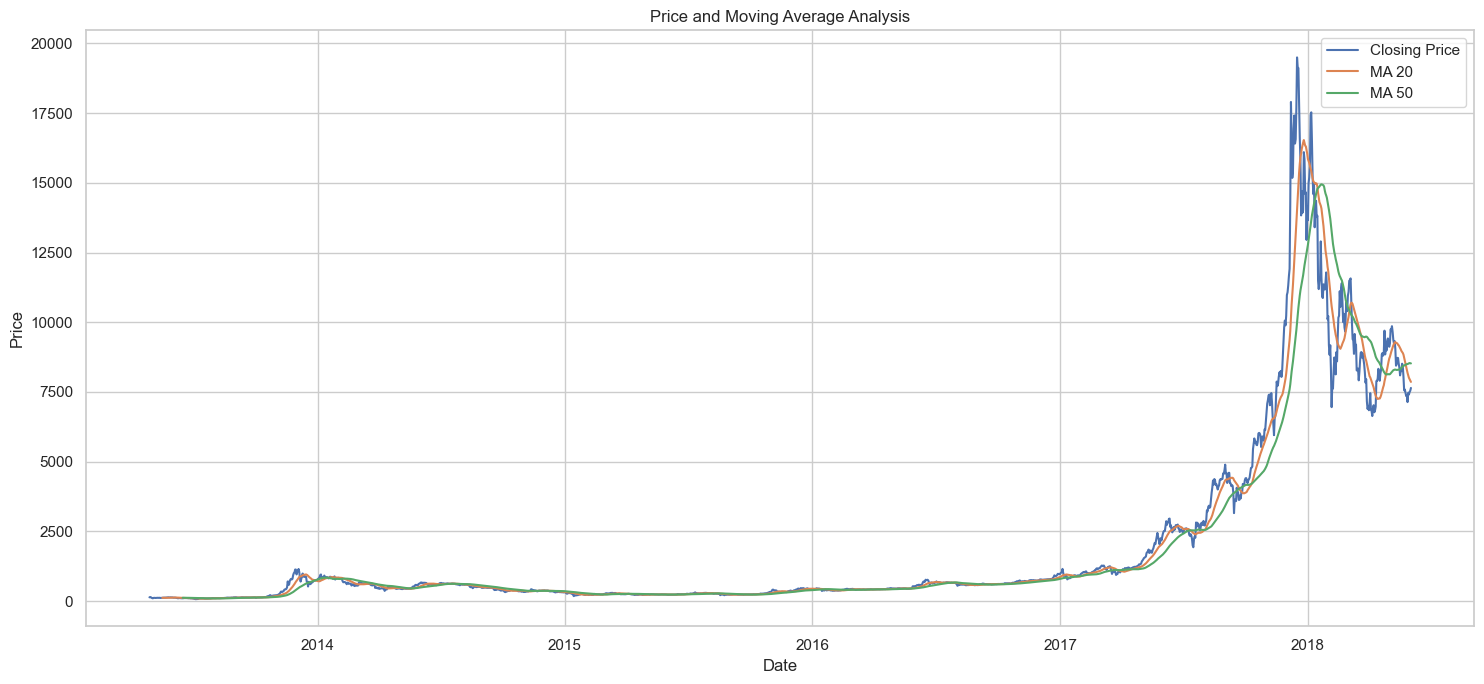

In [22]:
plt.figure(figsize=(15, 7))

plt.plot(
    coin["date"],
    coin["close"],
    label="Closing Price"
)

plt.plot(
    coin["date"],
    coin["ma_20"],
    label="MA 20"
)

plt.plot(
    coin["date"],
    coin["ma_50"],
    label="MA 50"
)

plt.title("Price and Moving Average Analysis")

plt.xlabel("Date")

plt.ylabel("Price")

plt.legend()

plt.tight_layout()

plt.show()

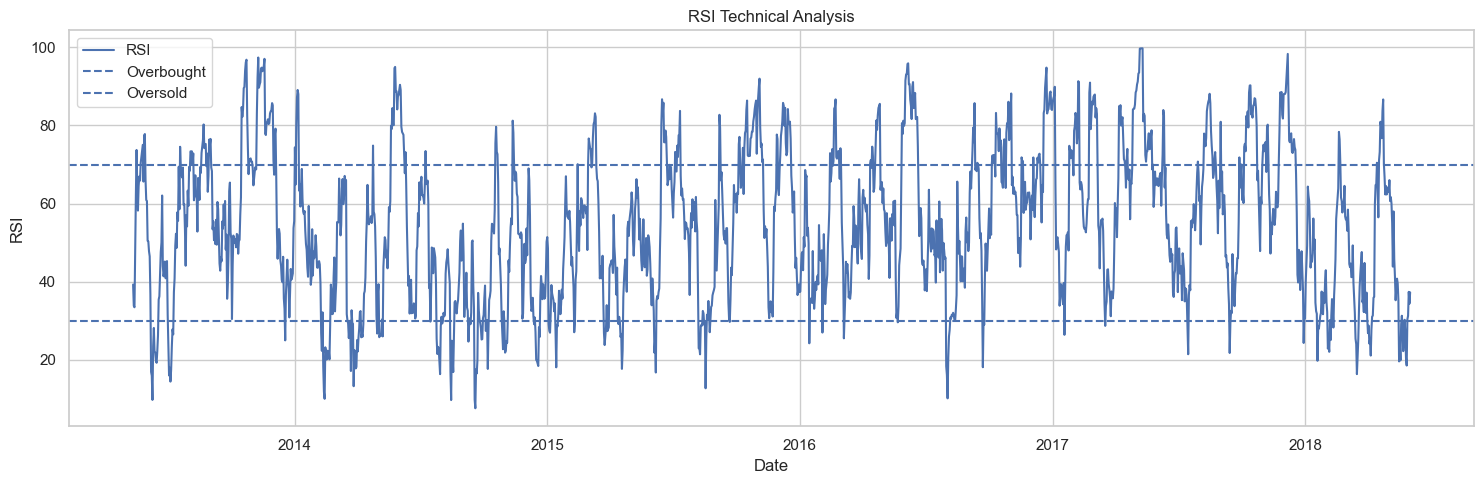

In [23]:
plt.figure(figsize=(15, 5))

plt.plot(
    coin["date"],
    coin["rsi"],
    label="RSI"
)

plt.axhline(
    70,
    linestyle="--",
    label="Overbought"
)

plt.axhline(
    30,
    linestyle="--",
    label="Oversold"
)

plt.title("RSI Technical Analysis")

plt.xlabel("Date")

plt.ylabel("RSI")

plt.legend()

plt.tight_layout()

plt.show()

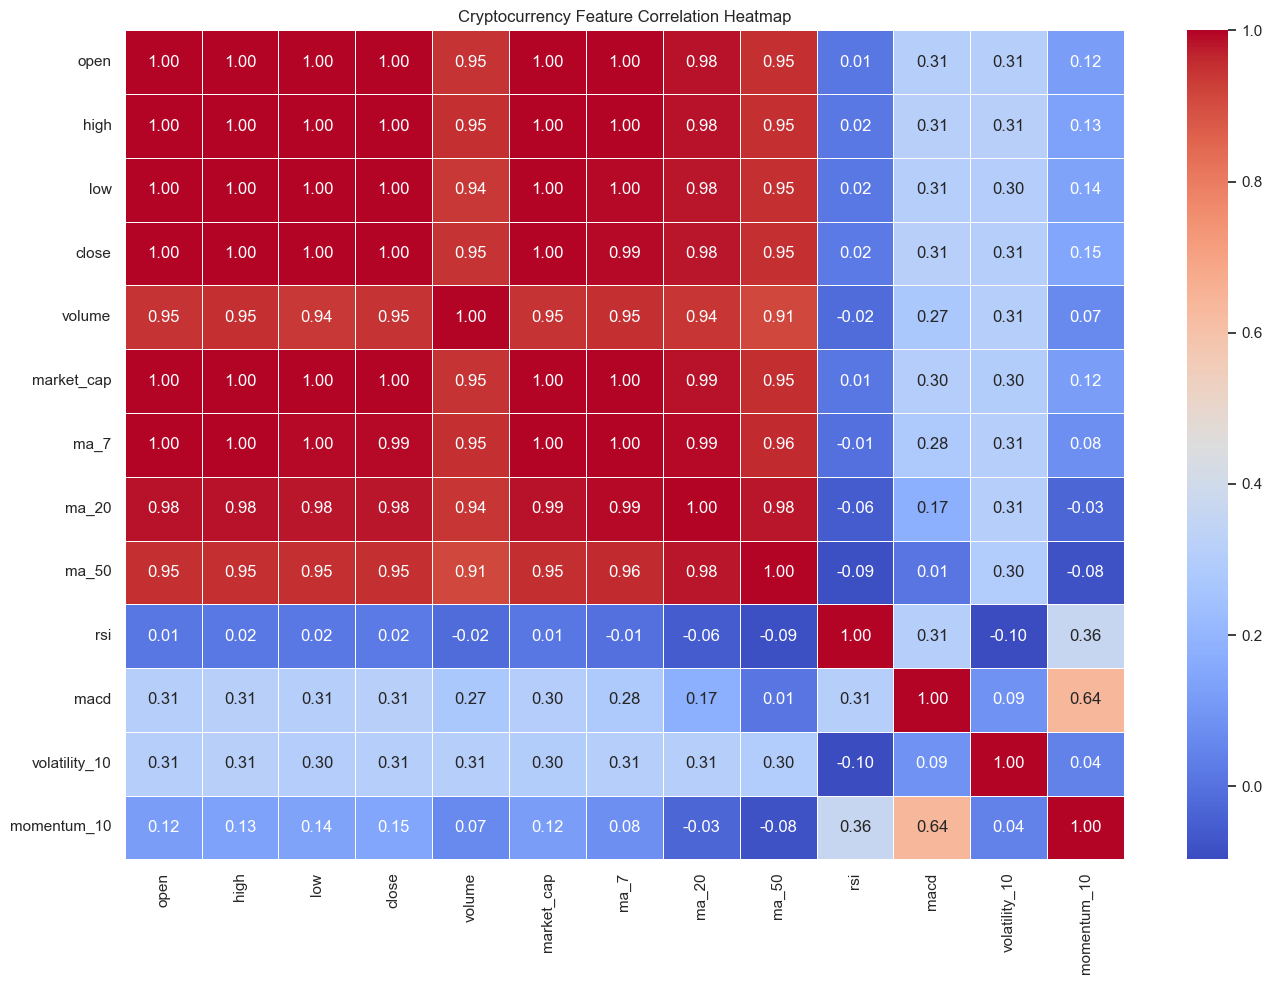

In [24]:
correlation_columns = [
    "open",
    "high",
    "low",
    "close",
    "volume",
    "market_cap",
    "ma_7",
    "ma_20",
    "ma_50",
    "rsi",
    "macd",
    "volatility_10",
    "momentum_10"
]

correlation_matrix = coin[
    correlation_columns
].corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Cryptocurrency Feature Correlation Heatmap")

plt.tight_layout()

plt.show()

# 4.Predictive analysis

In [25]:
# Target: next day's percentage return

coin["target_next_return"] = (
    coin["close"].shift(-1) / coin["close"] - 1
)

# Target: next day's closing price

coin["target_next_close"] = (
    coin["close"].shift(-1)
)

print("Prediction targets created!")

display(
    coin[
        [
            "date",
            "close",
            "target_next_close",
            "target_next_return"
        ]
    ].tail()
)

Prediction targets created!


,date,close,target_next_close,target_next_return
1857,2018-05-29,7472.59,7406.52,-0.008842
1858,2018-05-30,7406.52,7494.17,0.011834
1859,2018-05-31,7494.17,7541.45,0.006309
1860,2018-06-01,7541.45,7643.45,0.013525
1861,2018-06-02,7643.45,NaN,NaN


In [26]:
features = [

    "open",
    "high",
    "low",
    "close",

    "volume",
    "market_cap",

    "volume_missing",
    "market_cap_missing",

    "returns",
    "log_returns",

    "ma_7",
    "ma_20",
    "ma_50",
    "ma_100",

    "ema_12",
    "ema_26",

    "macd",
    "macd_signal",

    "rsi",

    "bb_upper",
    "bb_lower",

    "volatility_10",
    "volatility_20",

    "momentum_10",

    "range_pct",
    "close_to_ma20"
]

# Remove rows with insufficient historical indicators

model_data = coin.dropna(
    subset=features + ["target_next_return", "target_next_close"]
).copy()

X = model_data[features]

y = model_data["target_next_return"]

print("Feature Count:", len(features))

print("Total Model Records:", len(model_data))

print("Feature Dataset Shape:", X.shape)

print("Target Dataset Shape:", y.shape)

Feature Count: 26
Total Model Records: 1762
Feature Dataset Shape: (1762, 26)
Target Dataset Shape: (1762,)


In [27]:
split_index = int(
    len(model_data) * 0.80
)

X_train = X.iloc[:split_index]

X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]

y_test = y.iloc[split_index:]

print("Training Records:", len(X_train))

print("Testing Records:", len(X_test))

print(
    "Training End Date:",
    model_data["date"].iloc[split_index - 1]
)

print(
    "Testing Start Date:",
    model_data["date"].iloc[split_index]
)

Training Records: 1409
Testing Records: 353
Training End Date: 2017-06-13 00:00:00
Testing Start Date: 2017-06-14 00:00:00


In [28]:
rf = RandomForestRegressor(

    n_estimators=300,

    max_depth=12,

    min_samples_split=5,

    min_samples_leaf=2,

    random_state=42,

    n_jobs=-1
)

rf.fit(
    X_train,
    y_train
)

print("Random Forest Model Training Completed!")

Random Forest Model Training Completed!


In [29]:
rf_return_pred = rf.predict(X_test)

# Convert predicted return into predicted price

current_test_price = X_test["close"].values

rf_pred = (
    current_test_price *
    (1 + rf_return_pred)
)

print("Random Forest Predicted Prices:")

print(rf_pred[:10])

Random Forest Predicted Prices:
[2529.41091085 2499.76472511 2547.31020773 2671.91787243 2593.23724265
 2640.59470466 2747.89572958 2734.69685783 2720.40388882 2735.85664101]


In [30]:
xgb = XGBRegressor(

    n_estimators=400,

    learning_rate=0.03,

    max_depth=4,

    min_child_weight=3,

    subsample=0.8,

    colsample_bytree=0.8,

    reg_lambda=1,

    objective="reg:squarederror",

    random_state=42,

    n_jobs=-1
)

xgb.fit(
    X_train,
    y_train
)

print("XGBoost Training Completed!")

XGBoost Training Completed!


In [31]:
xgb_return_pred = xgb.predict(X_test)

# Convert predicted return into predicted price

xgb_pred = (
    current_test_price *
    (1 + xgb_return_pred)
)

print("XGBoost Predicted Prices:")

print(xgb_pred[:10])

XGBoost Predicted Prices:
[2545.46361004 2524.39461735 2547.42376413 2701.15459621 2601.86916936
 2626.5426527  2762.01525731 2762.8387664  2742.32320502 2753.46284424]


In [32]:
y_test_price = model_data[
    "target_next_close"
].iloc[split_index:].values

def evaluate_model(actual, predicted):

    mae = mean_absolute_error(
        actual,
        predicted
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual,
            predicted
        )
    )

    r2 = r2_score(
        actual,
        predicted
    )

    mape = np.mean(
        np.abs(
            (actual - predicted) /
            np.maximum(np.abs(actual), 1e-8)
        )
    ) * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2,
        "MAPE": mape
    }

rf_metrics = evaluate_model(
    y_test_price,
    rf_pred
)

xgb_metrics = evaluate_model(
    y_test_price,
    xgb_pred
)

print("RANDOM FOREST RESULTS")

print(rf_metrics)

print("\nXGBOOST RESULTS")

print(xgb_metrics)

RANDOM FOREST RESULTS
{'MAE': 367.44172503856635, 'RMSE': np.float64(579.3119175728859), 'R2 Score': 0.978968106268195, 'MAPE': np.float64(4.392990836729592)}

XGBOOST RESULTS
{'MAE': 376.89468222123367, 'RMSE': np.float64(628.7466391140471), 'R2 Score': 0.9752255052537702, 'MAPE': np.float64(4.486856629530956)}


In [33]:
baseline_pred = X_test["close"].values

baseline_metrics = evaluate_model(
    y_test_price,
    baseline_pred
)

print("NAIVE BASELINE RESULTS")

print(baseline_metrics)

NAIVE BASELINE RESULTS
{'MAE': 332.01274787535414, 'RMSE': np.float64(544.5511652478623), 'R2 Score': 0.9814163577487974, 'MAPE': np.float64(3.978540051505929)}


In [34]:
results = pd.DataFrame({

    "Model": [
        "Naive Baseline",
        "Random Forest",
        "XGBoost"
    ],

    "MAE": [
        baseline_metrics["MAE"],
        rf_metrics["MAE"],
        xgb_metrics["MAE"]
    ],

    "RMSE": [
        baseline_metrics["RMSE"],
        rf_metrics["RMSE"],
        xgb_metrics["RMSE"]
    ],

    "R2 Score": [
        baseline_metrics["R2 Score"],
        rf_metrics["R2 Score"],
        xgb_metrics["R2 Score"]
    ],

    "MAPE": [
        baseline_metrics["MAPE"],
        rf_metrics["MAPE"],
        xgb_metrics["MAPE"]
    ]

})

display(
    results.round(4)
)

,Model,MAE,RMSE,R2 Score,MAPE
0,Naive Baseline,332.0127,544.5512,0.9814,3.9785
1,Random Forest,367.4417,579.3119,0.9790,4.3930
2,XGBoost,376.8947,628.7466,0.9752,4.4869


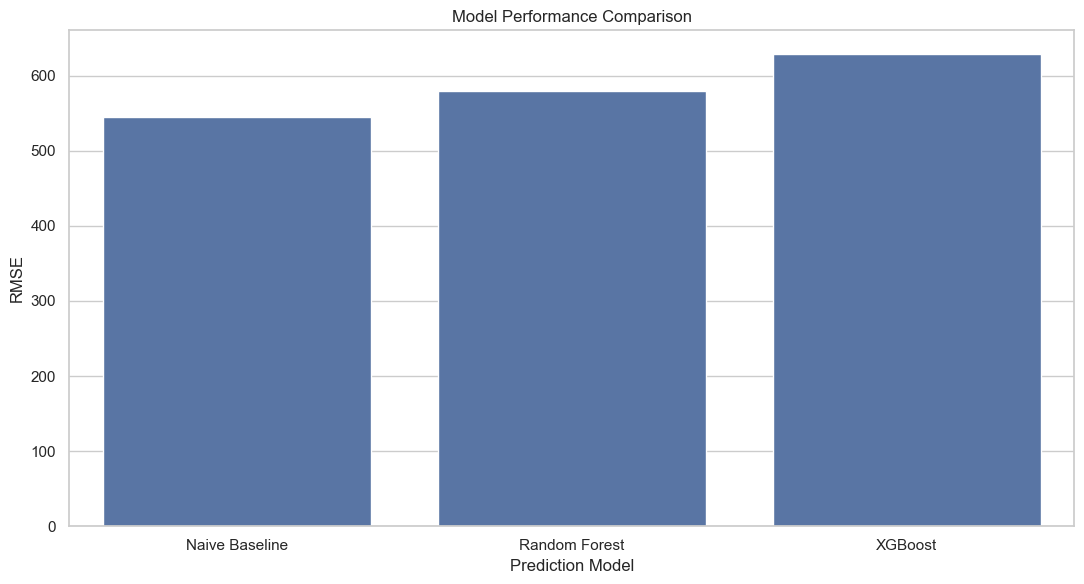

In [35]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=results,
    x="Model",
    y="RMSE"
)

plt.title("Model Performance Comparison")

plt.xlabel("Prediction Model")

plt.ylabel("RMSE")

plt.tight_layout()

plt.show()

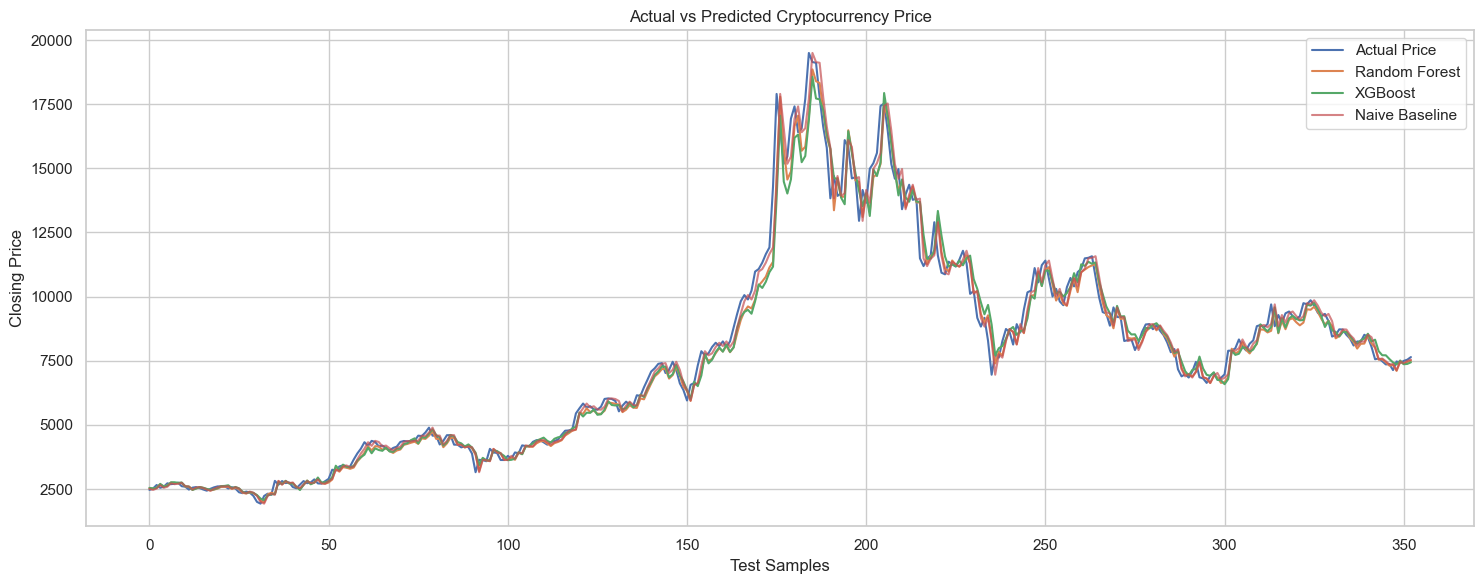

In [36]:
plt.figure(figsize=(15, 6))

plt.plot(
    y_test_price,
    label="Actual Price"
)

plt.plot(
    rf_pred,
    label="Random Forest"
)

plt.plot(
    xgb_pred,
    label="XGBoost"
)

plt.plot(
    baseline_pred,
    label="Naive Baseline",
    alpha=0.7
)

plt.title("Actual vs Predicted Cryptocurrency Price")

plt.xlabel("Test Samples")

plt.ylabel("Closing Price")

plt.legend()

plt.tight_layout()

plt.show()

# 5.Advance model analysis

In [37]:
importance = pd.DataFrame({

    "Feature": features,

    "Importance": rf.feature_importances_

})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

display(
    importance
)

,Feature,Importance
25,close_to_ma20,0.176250
24,range_pct,0.104464
9,log_returns,0.076095
8,returns,0.070241
18,rsi,0.064750
22,volatility_20,0.064004
23,momentum_10,0.056954
17,macd_signal,0.053296
21,volatility_10,0.045576
4,volume,0.040998


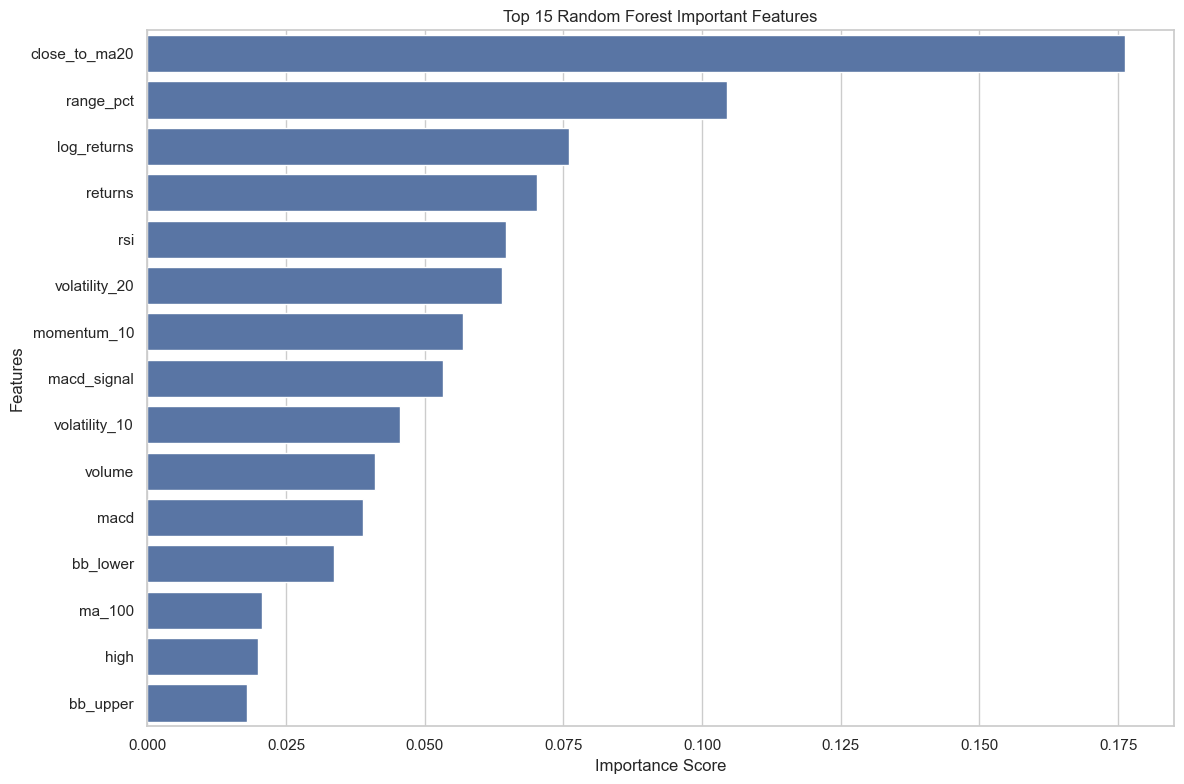

In [38]:
plt.figure(figsize=(12, 8))

sns.barplot(
    data=importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Random Forest Important Features")

plt.xlabel("Importance Score")

plt.ylabel("Features")

plt.tight_layout()

plt.show()

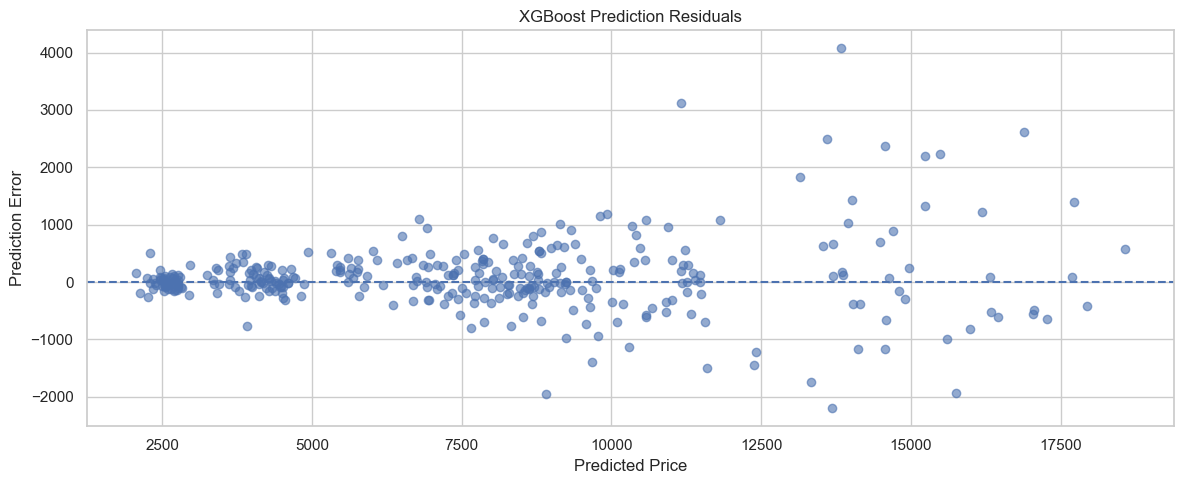

In [39]:
residuals = (
    y_test_price - xgb_pred
)

plt.figure(figsize=(12, 5))

plt.scatter(
    xgb_pred,
    residuals,
    alpha=0.6
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.title("XGBoost Prediction Residuals")

plt.xlabel("Predicted Price")

plt.ylabel("Prediction Error")

plt.tight_layout()

plt.show()

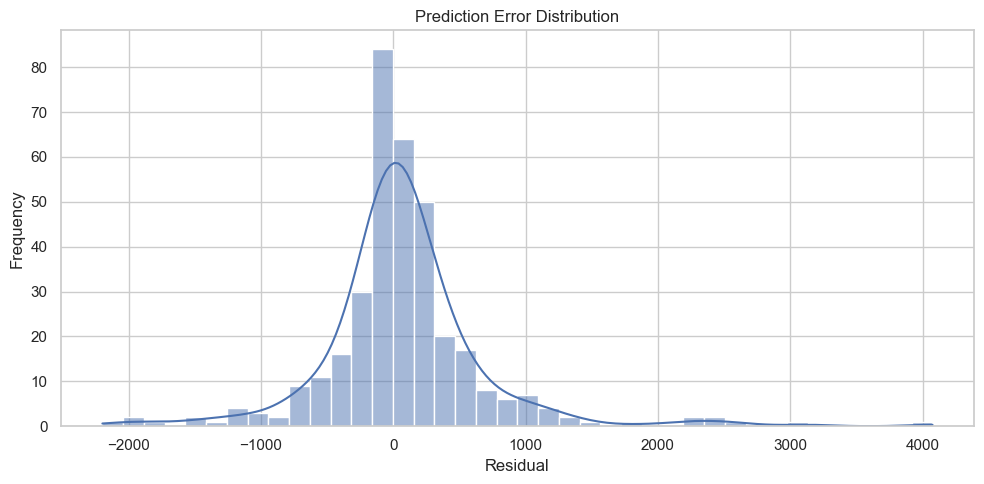

In [40]:
plt.figure(figsize=(10, 5))

sns.histplot(
    residuals,
    bins=40,
    kde=True
)

plt.title("Prediction Error Distribution")

plt.xlabel("Residual")

plt.ylabel("Frequency")

plt.tight_layout()

plt.show()

# 6.Prescriptive analytics

In [41]:
prediction_df = model_data.iloc[
    split_index:
].copy()

prediction_df["actual_next_close"] = y_test_price

prediction_df["predicted_price"] = xgb_pred

# Calculate expected price movement

prediction_df["expected_change"] = (

    (prediction_df["predicted_price"] -
     prediction_df["close"])

    / prediction_df["close"]

) * 100

# Trading signals

prediction_df["signal"] = np.select(

    [
        prediction_df["expected_change"] > 0.5,

        prediction_df["expected_change"] < -0.5
    ],

    [
        "BUY",

        "SELL"
    ],

    default="HOLD"
)

display(
    prediction_df[
        [
            "date",
            "close",
            "predicted_price",
            "expected_change",
            "signal"
        ]
    ].head(20)
)

,date,close,predicted_price,expected_change,signal
1508,2017-06-14,2506.37,2545.463610,1.559770,BUY
1509,2017-06-15,2464.58,2524.394617,2.426970,BUY
1510,2017-06-16,2518.56,2547.423764,1.146042,BUY
1511,2017-06-17,2655.88,2701.154596,1.704693,BUY
1512,2017-06-18,2548.29,2601.869169,2.102554,BUY
1513,2017-06-19,2589.60,2626.542653,1.426578,BUY
1514,2017-06-20,2721.79,2762.015257,1.477897,BUY
1515,2017-06-21,2689.10,2762.838766,2.742136,BUY
1516,2017-06-22,2705.41,2742.323205,1.364422,BUY
1517,2017-06-23,2744.91,2753.462844,0.311589,HOLD


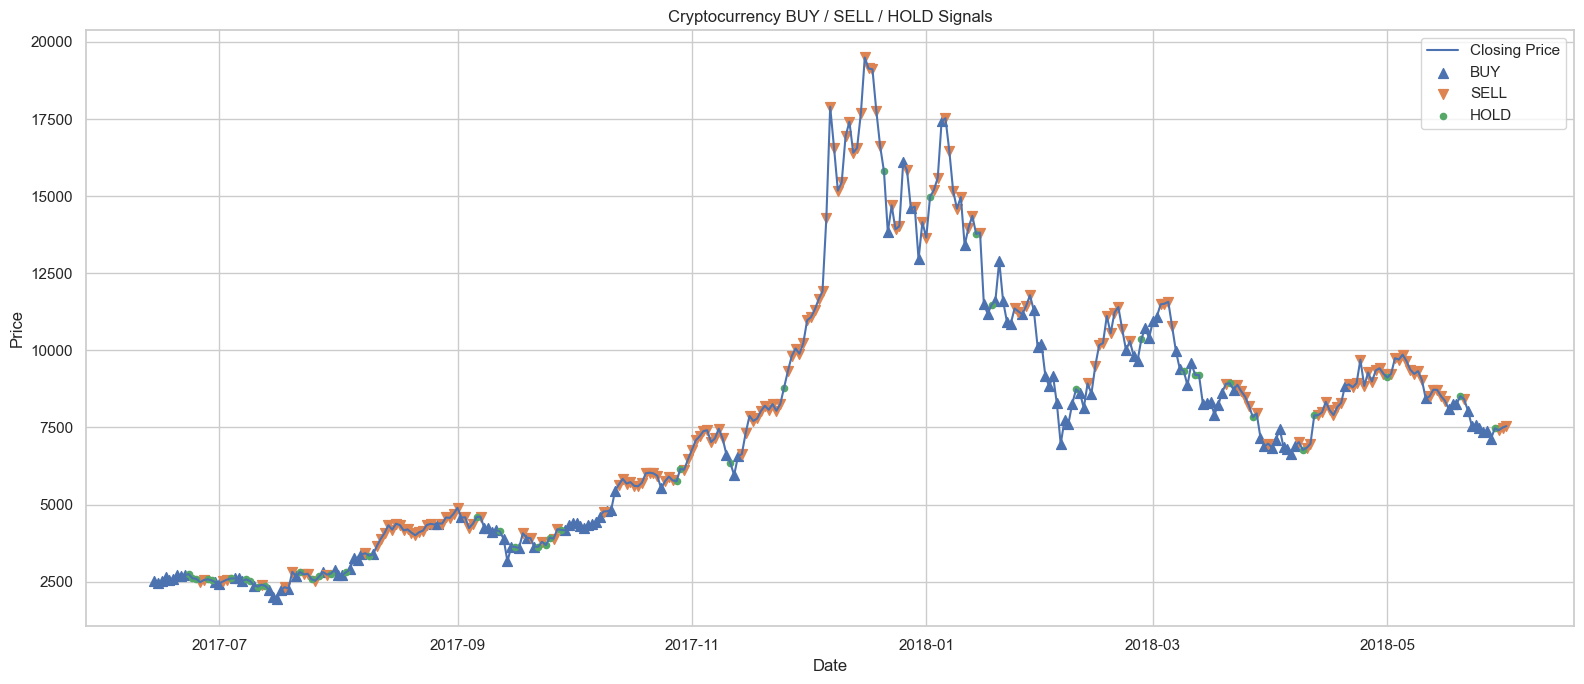

In [42]:
plt.figure(figsize=(16, 7))

plt.plot(
    prediction_df["date"],
    prediction_df["close"],
    label="Closing Price"
)

buy = prediction_df[
    prediction_df["signal"] == "BUY"
]

sell = prediction_df[
    prediction_df["signal"] == "SELL"
]

hold = prediction_df[
    prediction_df["signal"] == "HOLD"
]

plt.scatter(
    buy["date"],
    buy["close"],
    marker="^",
    label="BUY",
    s=50
)

plt.scatter(
    sell["date"],
    sell["close"],
    marker="v",
    label="SELL",
    s=50
)

plt.scatter(
    hold["date"],
    hold["close"],
    marker="o",
    label="HOLD",
    s=20
)

plt.title("Cryptocurrency BUY / SELL / HOLD Signals")

plt.xlabel("Date")

plt.ylabel("Price")

plt.legend()

plt.tight_layout()

plt.show()

TRADING SIGNAL SUMMARY


signal
SELL    183
BUY     127
HOLD     43
Name: count, dtype: int64

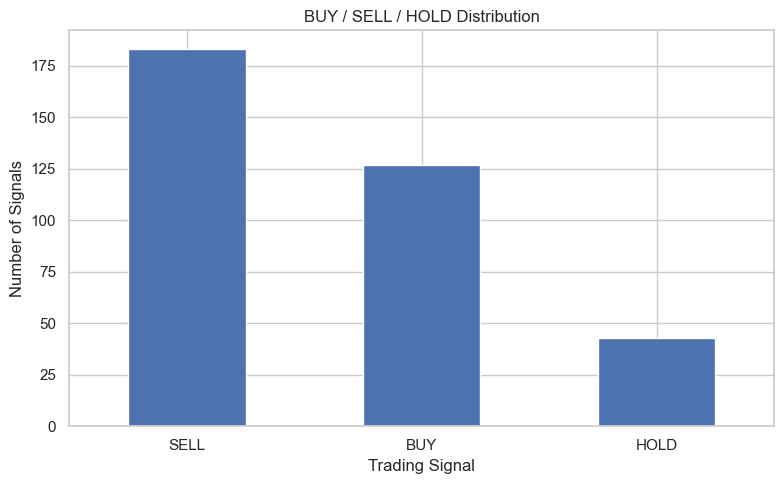

In [43]:
signal_counts = prediction_df[
    "signal"
].value_counts()

print("TRADING SIGNAL SUMMARY")

display(signal_counts)

plt.figure(figsize=(8, 5))

signal_counts.plot(
    kind="bar"
)

plt.title("BUY / SELL / HOLD Distribution")

plt.xlabel("Trading Signal")

plt.ylabel("Number of Signals")

plt.xticks(rotation=0)

plt.tight_layout()

plt.show()

# 7.Cognitive analysis

In [44]:
def ai_reasoning(row):

    high_volatility = (
        row["volatility_20"] >
        coin["volatility_20"].quantile(0.90)
    )

    if high_volatility:

        return (
            "High market volatility detected. "
            "Price movements may be unpredictable."
        )

    elif (
        row["rsi"] < 30
        and row["expected_change"] > 0.5
    ):

        return (
            "Market appears oversold. "
            "Model predicts an upward price movement."
        )

    elif (
        row["rsi"] > 70
        and row["expected_change"] < -0.5
    ):

        return (
            "Market appears overbought. "
            "Model predicts a downward price movement."
        )

    elif (
        row["macd"] > row["macd_signal"]
        and row["expected_change"] > 0
    ):

        return (
            "Positive momentum detected. "
            "Model predicts possible upward movement."
        )

    elif (
        row["macd"] < row["macd_signal"]
        and row["expected_change"] < 0
    ):

        return (
            "Negative momentum detected. "
            "Model predicts possible downward movement."
        )

    else:

        return (
            "Mixed market indicators detected. "
            "Monitor the market before making decisions."
        )

In [45]:
prediction_df["AI_Reasoning"] = (
    prediction_df.apply(
        ai_reasoning,
        axis=1
    )
)

display(

    prediction_df[
        [
            "date",
            "close",
            "predicted_price",
            "rsi",
            "macd",
            "signal",
            "AI_Reasoning"
        ]
    ].tail(20)

)

,date,close,predicted_price,rsi,macd,signal,AI_Reasoning
1841,2018-05-13,8723.94,8618.995634,38.434534,82.929014,SELL,Negative momentum detected. Model predicts pos...
1842,2018-05-14,8716.79,8619.297464,40.758894,53.012719,SELL,Negative momentum detected. Model predicts pos...
1843,2018-05-15,8510.38,8466.741086,39.573719,12.504138,SELL,Negative momentum detected. Model predicts pos...
1844,2018-05-16,8368.83,8283.666267,35.270455,-30.667590,SELL,Negative momentum detected. Model predicts pos...
1845,2018-05-17,8094.32,8165.616836,19.565009,-86.040338,BUY,Market appears oversold. Model predicts an upw...
1846,2018-05-18,8250.97,8292.992996,24.326277,-115.946733,BUY,Market appears oversold. Model predicts an upw...
1847,2018-05-19,8247.18,8367.391535,19.830780,-138.358675,BUY,Market appears oversold. Model predicts an upw...
1848,2018-05-20,8513.25,8551.968881,29.112460,-133.116194,HOLD,Mixed market indicators detected. Monitor the ...
1849,2018-05-21,8418.99,8252.107263,31.257564,-135.011160,SELL,Negative momentum detected. Model predicts pos...
1850,2018-05-22,8041.78,8320.129279,28.574045,-165.048058,BUY,Market appears oversold. Model predicts an upw...


# 8.Next-Day Cryptocurrency Forecast

In [46]:
# Get latest available feature record

latest_data = coin.dropna(
    subset=features
).iloc[[-1]]

# Predict next-day return

next_return = xgb.predict(
    latest_data[features]
)[0]

# Current closing price

current_price = latest_data[
    "close"
].iloc[0]

# Calculate predicted price

next_day_prediction = (
    current_price * (1 + next_return)
)

# Percentage change

price_change = next_return * 100

print("CRYPTOCURRENCY:", COIN_SYMBOL)

print("LATEST AVAILABLE DATE:")

print(latest_data["date"].iloc[0])

print("\nCURRENT CLOSING PRICE:")

print(current_price)

print("\nPREDICTED NEXT-DAY PRICE:")

print(next_day_prediction)

print("\nEXPECTED PRICE CHANGE:")

print(round(price_change, 2), "%")

CRYPTOCURRENCY: ETH
LATEST AVAILABLE DATE:
2018-06-02 00:00:00

CURRENT CLOSING PRICE:
7643.45

PREDICTED NEXT-DAY PRICE:
7387.088607108592

EXPECTED PRICE CHANGE:
-3.35 %


In [47]:
if price_change > 0.5:

    next_signal = "BUY"

elif price_change < -0.5:

    next_signal = "SELL"

else:

    next_signal = "HOLD"

print("NEXT-DAY SIGNAL:", next_signal)

NEXT-DAY SIGNAL: SELL


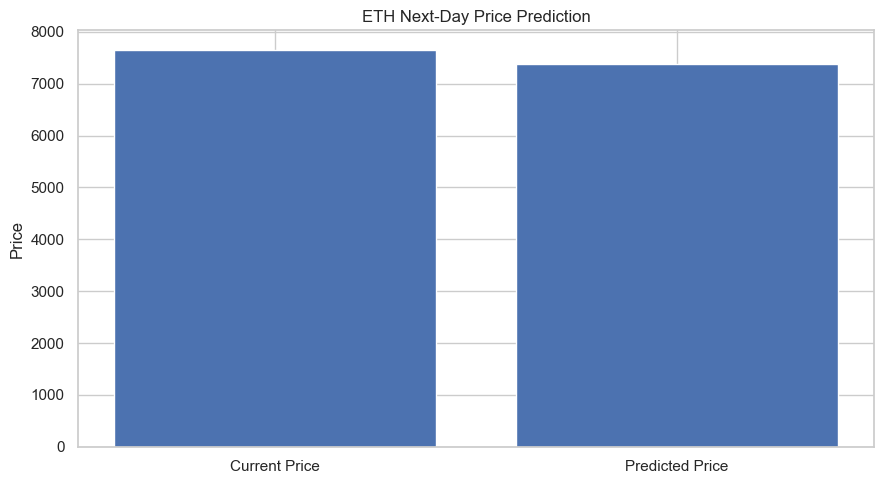

In [48]:
plt.figure(figsize=(9, 5))

plt.bar(

    ["Current Price", "Predicted Price"],

    [
        current_price,
        next_day_prediction
    ]

)

plt.title(
    f"{COIN_SYMBOL} Next-Day Price Prediction"
)

plt.ylabel("Price")

plt.tight_layout()

plt.show()

# 9.Final analytics dashboard

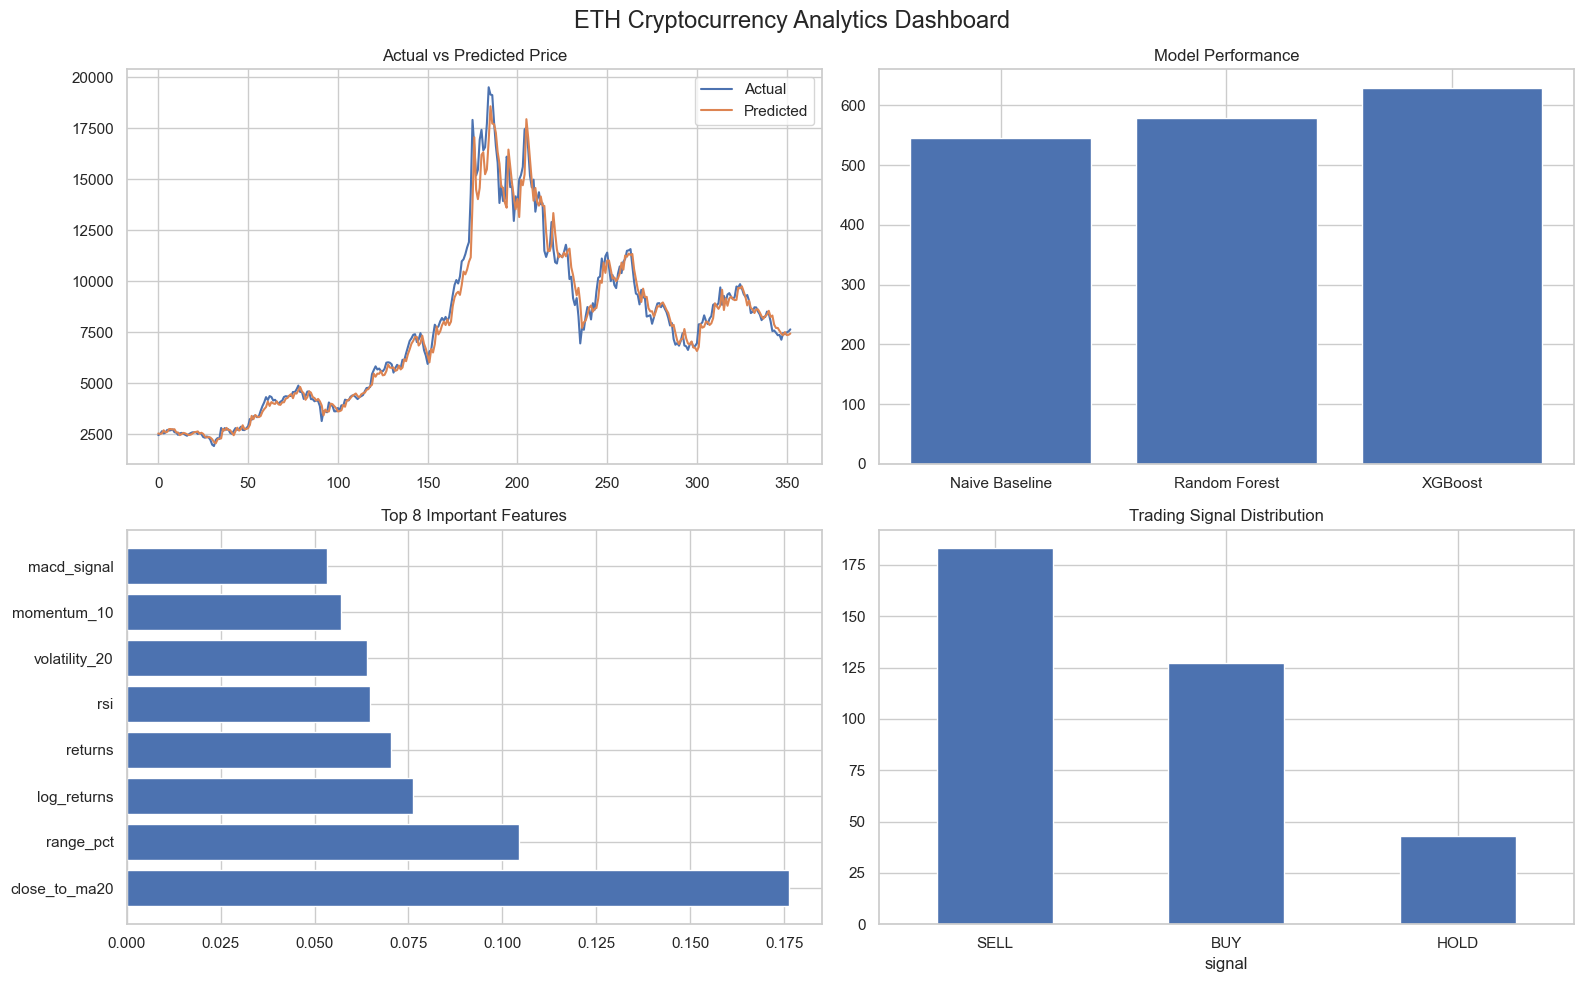

In [49]:
fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 10)
)

# 1. Actual vs predicted

axes[0, 0].plot(
    y_test_price,
    label="Actual"
)

axes[0, 0].plot(
    xgb_pred,
    label="Predicted"
)

axes[0, 0].set_title(
    "Actual vs Predicted Price"
)

axes[0, 0].legend()

# 2. Model comparison

axes[0, 1].bar(
    results["Model"],
    results["RMSE"]
)

axes[0, 1].set_title(
    "Model Performance"
)

# 3. Feature importance

top_features = importance.head(8)

axes[1, 0].barh(
    top_features["Feature"],
    top_features["Importance"]
)

axes[1, 0].set_title(
    "Top 8 Important Features"
)

# 4. Signal distribution

signal_counts.plot(
    kind="bar",
    ax=axes[1, 1]
)

axes[1, 1].set_title(
    "Trading Signal Distribution"
)

axes[1, 1].tick_params(
    axis="x",
    rotation=0
)

plt.suptitle(
    f"{COIN_SYMBOL} Cryptocurrency Analytics Dashboard",
    fontsize=17
)

plt.tight_layout()

plt.show()

In [50]:
print("=" * 55)

print("CRYPTOCURRENCY DATA ANALYTICS PROJECT")

print("=" * 55)

print("\nCRYPTOCURRENCY:", COIN_SYMBOL)

print("\nDATASET INFORMATION")

print("Total Historical Records:", len(coin))

print("Model Records:", len(model_data))

print("Training Samples:", len(X_train))

print("Testing Samples:", len(X_test))

print("\nMODEL PERFORMANCE")

display(results.round(4))

print("\nNEXT-DAY FORECAST")

print("Latest Price:", current_price)

print("Predicted Price:", next_day_prediction)

print("Expected Change:", round(price_change, 2), "%")

print("Predicted Signal:", next_signal)

print("\nPROJECT EXECUTION COMPLETED")

print("=" * 55)

CRYPTOCURRENCY DATA ANALYTICS PROJECT

CRYPTOCURRENCY: ETH

DATASET INFORMATION
Total Historical Records: 1862
Model Records: 1762
Training Samples: 1409
Testing Samples: 353

MODEL PERFORMANCE


,Model,MAE,RMSE,R2 Score,MAPE
0,Naive Baseline,332.0127,544.5512,0.9814,3.9785
1,Random Forest,367.4417,579.3119,0.9790,4.3930
2,XGBoost,376.8947,628.7466,0.9752,4.4869



NEXT-DAY FORECAST
Latest Price: 7643.45
Predicted Price: 7387.088607108592
Expected Change: -3.35 %
Predicted Signal: SELL

PROJECT EXECUTION COMPLETED
